# Further model tuning: five Kaggle candidates

All development work is in this notebook. Existing `final_model_improvements.ipynb` supplies the reviewed definitions. Training outputs, caches, metrics, frozen recipes and submission CSVs are artifacts. No test labels, pretrained models, external labeling, or Kaggle uploads.

Run from `submissions/team-35/plum/` using **Run All**. Completed experiments resume from validated artifacts. Dependencies are those of the previous notebook; no packages were added.

The temporary conversion scripts and planning files were discarded. The notebook is the only new source file; all other outputs are experiment artifacts.

**Prerequisite:** run `final_model_improvements.ipynb` once if its audited splits, baseline predictions and environment artifacts are absent. This notebook verifies their supplied-data hashes and reuses its feature/model definitions. Optional model-feature caches accelerate the run; they are not sources of labels. For a new search after changing configurations, use a new `OUT` artifact directory so the frozen recipes and this run remain intact.

# Five further submission candidates

All new files and training outputs stay in `submissions/team-35/plum`. Supplied competition CSVs are read-only inputs. Existing notebooks, report, configuration and submissions are preserved.

## Evidence and constraints

The assignment uses AUROC, requires the same stratified seed-42 8,000/2,000 partition for controlled comparisons, permits a final 10,000-row refit, and forbids external supervised labels or LLM test prediction. The previous notebook retained corrected v3 after its candidates failed promotion; SSL showed no confirmed gain. Its outer development original/canonical/wrap90 AUROCs were 0.997947/0.968697/0.975870. Historical inspection means the official holdout is not a pristine estimate.

## Ordered tasks

1. Reuse the notebook's feature/model definitions without executing its experiment or export cells. Verify definition hashes, data hashes, grouped fold membership, and existing model contracts. Add tests for candidate selection and CSV integrity before implementation.
2. Run five grouped development folds for a bounded first round of longer, regularized LightGBM/CatBoost/XGBoost fits with word and character LM features. Retain fold-local human references and nested LM training. Save every spec and prediction. Checkpoint: compare original AUROC and six stress views with the incumbent on identical folds.
3. Adapt the next round to observed results: test formatting augmentation and blend the strongest complementary procedures. Select five distinct procedures using development predictions only, with an original-AUROC guardrail and improvement in formatting stress. Confirm domain holdouts and another fold seed; record any failed hypotheses. Checkpoint: freeze all five recipes before reading new holdout predictions. Search scores are selection-biased and are not final generalization estimates.
4. Evaluate the frozen recipes and incumbent once on the fixed 2,000-row holdout (with cross-boundary duplicate sensitivity). Do not retune or reorder using that holdout. Record paired uncertainty and subgroup/stress results.
5. Refit required branches on all 10,000 labels, average independently seeded fits where development evidence supports it, and produce exactly five CSVs in `artifacts/further_tuning/submissions/`. Verify 3,000 unique IDs in sample order, exact column names, finite probabilities in [0,1], distinct predictions, deterministic rerun, hashes, and reproducible commands. Update graphify and write results with upload order.

## Implementation decisions

- Reuse the reviewed engine rather than fork the feature implementation. Historical cache entries may be read only when the entire original implementation/configuration/data/fold key matches; all new writes use a dedicated cache.
- More trees are hypotheses, not success criteria. Tune learning rate jointly with tree count and regularization. Enable LightGBM `subsample_freq` when testing row subsampling.
- Prefer genuinely different validated ensembles over changing only probability calibration (which cannot improve AUROC).
- Before blend selection, fix the development promotion rule: original AUROC may decline by at most 0.0006, the mean canonical/wrap60/wrap90 AUROC must rise by at least 0.003, and the average of original AUROC and that stress mean must rise by at least 0.001. Each candidate must satisfy all three. These guardrails prioritize the known adversarial-formatting weakness without discarding ordinary validation performance.
- No test-label access, external pretrained downloads, paid compute, test pseudo-labels, or Kaggle upload.

## References

- `report/report_draft.tex`: assignment rules.
- `final_model_improvements.ipynb` and its saved artifacts: baseline and training engine.
- https://lightgbm.readthedocs.io/en/stable/Parameters.html
- https://catboost.ai/docs/en/concepts/parameter-tuning
- https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html

## Limits

Kaggle improvement is an expectation based on validation, not an observed result. The unknown private-domain mixture and historical holdout reuse limit confidence. If a round fails, retain its negative results and investigate the next supported change rather than silently manufacturing five claims.


In [1]:
"""Reproducible further tuning: run this notebook from its own directory."""


import ast


import copy


import hashlib


import json


import sys


import time


import types


from pathlib import Path


import numpy as np


import pandas as pd


from scipy.special import expit, logit


from sklearn.metrics import roc_auc_score


ROOT = Path.cwd().resolve()


OLD = ROOT / 'artifacts/final_model_improvements'


OUT = ROOT / 'artifacts/further_tuning'


KINDS = ['original', 'canonical', 'typography', 'lowercase', 'wrap60', 'wrap90']


## Core contracts

In [2]:
def write_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, default=lambda x: x.item() if isinstance(x, np.generic) else str(x)), encoding='utf-8')


def combine(predictions, weights):
    if any(w < 0 for w in weights.values()) or not np.isclose(sum(weights.values()), 1.):
        raise ValueError('Blend weights must be a nonnegative simplex.')
    return expit(sum(w * logit(np.clip(predictions[name], 1e-7, 1-1e-7)) for name, w in weights.items()))


def validate_submission(frame, sample):
    if list(frame.columns) != list(sample.columns) or len(frame) != len(sample):
        raise ValueError('Submission schema or row count differs from the sample.')
    if not frame.id.is_unique or not frame.id.equals(sample.id):
        raise ValueError('Submission IDs must be unique and in sample order.')
    values = frame.iloc[:, 1].to_numpy(dtype=float)
    if not np.isfinite(values).all() or not ((values >= 0) & (values <= 1)).all():
        raise ValueError('Probabilities must be finite and in [0,1].')


def scores(y, prediction):
    row = {kind: roc_auc_score(y, prediction[kind]) for kind in KINDS}
    row['stress_mean'] = np.mean([row[k] for k in ['canonical', 'wrap60', 'wrap90']])
    row['balanced'] = .5 * row['original'] + .5 * row['stress_mean']
    return row


def eligible(row, baseline):
    return (row['original'] >= baseline['original'] - .0006
            and row['stress_mean'] >= baseline['stress_mean'] + .003
            and row['balanced'] >= baseline['balanced'] + .001)


## Reuse the reviewed notebook engine

In [3]:
def load_engine():
    """Load definition cells only; never run notebook experiments or its export cells."""
    notebook = json.loads((ROOT / 'final_model_improvements.ipynb').read_text(encoding='utf-8'))
    source = lambda cell: ''.join(cell['source'])
    module = types.ModuleType('plum_reused_engine')
    sys.modules[module.__name__] = module
    namespace = module.__dict__
    setup = ast.parse(source(notebook['cells'][1]))
    imports = ast.Module(body=[n for n in setup.body if isinstance(n, (ast.Import, ast.ImportFrom))], type_ignores=[])
    exec(compile(imports, 'notebook_imports', 'exec'), namespace)
    cfg = namespace['yaml'].safe_load((ROOT / 'models/final_model_improvements.yaml').read_text())
    configs = [namespace['yaml'].safe_load((ROOT / cfg['baseline_sources'][k]).read_text()) for k in ['v0', 'v2', 'v3', 'nb', 'lm']]
    implementation_hash = hashlib.sha256(''.join(source(c) for c in notebook['cells'] if c['cell_type'] == 'code' and set(c.get('metadata', {}).get('tags', [])) & {'setup', 'feature-definitions', 'model-definitions', 'test-definitions'}).encode()).hexdigest()
    versions = {p: namespace['metadata'].version(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'lightgbm', 'catboost', 'xgboost', 'PyYAML', 'joblib']}
    config_hash = namespace['joblib'].hash((cfg, *configs, 'full', versions, implementation_hash))
    prior = json.loads((OLD / 'environment.json').read_text())
    namespace.update(SUBMISSION_DIR=ROOT, cfg=cfg, SEED=42, THREADS=6, MODE='full', ART=OUT,
                     CACHE=OUT / 'cache', RUN_STARTED=time.time(), CONFIG_HASH=config_hash,
                     base0=configs[0], base2=configs[1], base3=configs[2], nb_cfg=configs[3], lm_cfg=configs[4])
    namespace['local_path'] = lambda relative: ROOT / relative
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / 'cache').mkdir(exist_ok=True)
    namespace['save_json'] = lambda name, obj: write_json(OUT / name, obj)
    def progress(message):
        line = f'[{(time.time()-namespace["RUN_STARTED"])/60:.1f} min] {message}'
        print(line, flush=True)
        with (OUT / 'progress.log').open('a', encoding='utf-8') as f:
            f.write(line + '\n')
    namespace['progress'] = progress
    namespace['threadpool_limits'](limits=6)
    for index in [5, 6, 7, 8, 9, 11, 12]:
        exec(compile(source(notebook['cells'][index]), f'final_model_improvements_cell_{index}', 'exec'), namespace)
    # Notebook-created sparse caches refer to their analyzer by __main__.
    setattr(sys.modules['__main__'], 'cached_ngrams', namespace['cached_ngrams'])
    # Original cache is read-only. Reuse requires its exact version/config/source key.
    reuse = config_hash == prior['config_hash'] and implementation_hash == prior['implementation_hash']
    def cached(kind, key, compute):
        filename = kind + '_' + namespace['joblib'].hash((config_hash, key)) + '.joblib'
        path = OUT / 'cache' / filename
        if path.exists():
            return namespace['joblib'].load(path)
        legacy = OLD / 'cache' / filename
        if reuse and legacy.exists():
            return namespace['joblib'].load(legacy)
        value = compute()
        namespace['joblib'].dump(value, path, compress=3 if kind == 'sparse_training' else 0)
        return value
    namespace['cached_result'] = cached
    namespace['test_contracts']()
    write_json(OUT / 'engine.json', {'implementation_hash': implementation_hash, 'config_hash': config_hash,
                                    'historical_cache_compatible': reuse, 'versions': versions})
    return namespace


def load_data(engine):
    # Match the notebook's documented, read-only supplied data location.
    configured = engine['cfg']['paths']['data_dir']
    paths = [ROOT / configured] if configured else [p / 'data' for p in [ROOT, *ROOT.parents]]
    data = next(p for p in paths if (p / 'train.csv').is_file() and (p / 'sample_submission.csv').is_file())
    old_env = json.loads((OLD / 'environment.json').read_text())
    for name, expected in old_env['data'].items():
        assert hashlib.sha256((data / name).read_bytes()).hexdigest() == expected, name
    train = pd.read_csv(data / 'train.csv')
    groups = pd.read_csv(OLD / 'duplicate_groups.csv').set_index('id')['group']
    train['group'] = train.id.map(groups)
    assert train.group.notna().all() and train.id.is_unique and set(train.label) == {0, 1}
    train['heuristic_domain'] = train.text.map(engine['classify_observable_domain'])
    ids = pd.read_csv(OLD / 'split_ids.csv')
    development = train.set_index('id').loc[ids.loc[ids.role == 'development', 'id']].reset_index()
    holdout = train.set_index('id').loc[ids.loc[ids.role == 'official_holdout', 'id']].reset_index()
    assert len(development) == 8000 and len(holdout) == 2000
    assert set(development.id).isdisjoint(holdout.id)
    return train, development, holdout, data


def evaluate(engine, development, name, spec, seed=42):
    folder = OUT / 'trials'
    folder.mkdir(exist_ok=True)
    prediction_path = folder / f'{name}_seed{seed}.csv'
    spec_path = folder / f'{name}.json'
    if spec_path.exists():
        assert json.loads(spec_path.read_text()) == spec, f'Changed existing trial {name}'
    write_json(spec_path, spec)
    if prediction_path.exists():
        prediction = pd.read_csv(prediction_path)
        assert prediction.id.equals(development.id)
        return {kind: prediction[kind].to_numpy() for kind in KINDS}
    predictions = {kind: np.full(len(development), np.nan) for kind in KINDS}
    folds = engine['make_folds'](development, 5, seed)
    for fold, (ti, vi) in enumerate(folds):
        target = engine['target_views'](development.iloc[vi], KINDS)
        values, _ = engine['fit_predict'](development.iloc[ti], target, spec, seed + fold)
        for j, kind in enumerate(KINDS):
            predictions[kind][vi] = values[j*len(vi):(j+1)*len(vi)]
        engine['progress'](f'{name} seed {seed} fold {fold+1}/5 AUC {roc_auc_score(development.label.iloc[vi], predictions["original"][vi]):.6f}')
    pd.DataFrame({'id': development.id, 'label': development.label, **predictions}).to_csv(prediction_path, index=False)
    return predictions


def incumbent(engine, development):
    names = ['lr_4v', 'svc_4v', 'mask_lr', 'lgb_pure', 'cat_pure', 'xgb_pure', 'lgb_struct', 'cat_struct', 'xgb_struct']
    branches = {}
    for name in names:
        frame = pd.read_csv(OLD / f'{name}_development_predictions.csv')
        assert frame.id.equals(development.id) and frame.label.equals(development.label)
        branches[name] = frame
    return {kind: engine['historical_fusions']({name: f[kind].to_numpy() for name, f in branches.items()})['B2_v3_corrected'] for kind in KINDS}


## Sequential tuning rounds

In [4]:
def first_round(engine):
    base = json.loads((OLD / 'F_char_lm_dense_spec.json').read_text())
    candidates = {}
    lgb_settings = [
        dict(n_estimators=1000, learning_rate=.025, num_leaves=15, min_child_samples=40, colsample_bytree=.85, reg_lambda=2.),
        dict(n_estimators=1600, learning_rate=.02, num_leaves=31, min_child_samples=40, colsample_bytree=.8, reg_lambda=5.),
        dict(n_estimators=1200, learning_rate=.025, num_leaves=31, min_child_samples=80, colsample_bytree=.7, reg_lambda=10.),
    ]
    for i, params in enumerate(lgb_settings):
        for structural in ['none', 'full']:
            spec = copy.deepcopy(base)
            spec['structural'] = structural
            spec['params'].update(params, subsample=.85, subsample_freq=1)
            candidates[f'lgb_{structural}_{i}'] = spec
    for depth, iterations, rate in [(5, 1800, .035), (6, 2400, .025)]:
        for structural in ['none', 'full']:
            spec = copy.deepcopy(base)
            spec.update(family='cat', structural=structural)
            spec['params'] = dict(iterations=iterations, learning_rate=rate, depth=depth, l2_leaf_reg=8., random_strength=.5, verbose=False)
            candidates[f'cat_{structural}_d{depth}'] = spec
    for structural in ['none', 'full']:
        spec = copy.deepcopy(base)
        spec.update(family='xgb', structural=structural)
        spec['params'] = dict(n_estimators=1400, learning_rate=.025, max_depth=4, min_child_weight=5, subsample=.85,
                              colsample_bytree=.8, reg_alpha=.1, reg_lambda=8.)
        candidates[f'xgb_{structural}_d4'] = spec
    return candidates


def search(engine, development):
    results = {'incumbent': scores(development.label, incumbent(engine, development))}
    for name, spec in first_round(engine).items():
        prediction = evaluate(engine, development, name, spec)
        results[name] = scores(development.label, prediction)
        pd.DataFrame.from_dict(results, orient='index').rename_axis('name').to_csv(OUT / 'round1.csv')
        engine['progress'](f'Completed {name}: {results[name]}')


def round2(engine, development):
    first = pd.read_csv(OUT / 'round1.csv').set_index('name')
    pure = first.loc[[n for n in first.index if '_none_' in n]].sort_values('balanced', ascending=False)
    full = first.loc[[n for n in first.index if '_full_' in n]].sort_values('original', ascending=False)
    candidates = {}
    for name in full.index[:2]:
        base = json.loads((OUT / 'trials' / f'{name}.json').read_text())
        for weight in [.15, .35, .7]:
            spec = copy.deepcopy(base)
            spec['augmentation'] = weight
            candidates[f'{name}_aug{int(100*weight)}'] = spec
    best = json.loads((OUT / 'trials' / f'{pure.index[0]}.json').read_text())
    spec = copy.deepcopy(best)
    spec['lm_settings']['char'] = copy.deepcopy(engine['lm_cfg']['char'])
    candidates['pure_char_order4'] = spec
    spec = copy.deepcopy(best)
    spec.update(canonical=True, improved=True, shrink=20)
    candidates['pure_canonical'] = spec
    write_json(OUT / 'round2_design.json', {'pure_ranking': pure.index.tolist(), 'structural_ranking': full.index.tolist(), 'specs': candidates})
    rows = []
    for name, spec in candidates.items():
        prediction = evaluate(engine, development, name, spec)
        rows.append({'name': name, **scores(development.label, prediction)})
        pd.DataFrame(rows).to_csv(OUT / 'round2.csv', index=False)
        engine['progress'](f'Completed {name}: {rows[-1]}')


## Development-only candidate selection

In [5]:
def trial_predictions(development):
    predictions = {}
    for path in sorted((OUT / 'trials').glob('*_seed42.csv')):
        frame = pd.read_csv(path)
        assert frame.id.equals(development.id)
        predictions[path.stem.removesuffix('_seed42')] = {kind: frame[kind].to_numpy() for kind in KINDS}
    return predictions


def propose(engine, development):
    """Five fixed structural fractions give distinct robustness tradeoffs."""
    predictions = trial_predictions(development)
    rows = {name: scores(development.label, p) for name, p in predictions.items()}
    pure = [name for name in rows if json.loads((OUT / 'trials' / f'{name}.json').read_text())['structural'] == 'none']
    pure = sorted(pure, key=lambda name: rows[name]['balanced'], reverse=True)[:3]
    structural = [name for name in rows if name not in pure and json.loads((OUT / 'trials' / f'{name}.json').read_text())['structural'] != 'none']
    baseline = scores(development.label, incumbent(engine, development))
    proposals, trials = [], []
    for fraction in [.65, .7, .75, .8, .85]:
        best = None
        for p in pure:
            for s in structural:
                weights = {p: 1-fraction, s: fraction}
                pred = {kind: combine({n: predictions[n][kind] for n in weights}, weights) for kind in KINDS}
                row = scores(development.label, pred)
                trials.append({'pure': p, 'structural': s, 'fraction': fraction, 'eligible': eligible(row, baseline), **row})
                if eligible(row, baseline) and (best is None or row['balanced'] > best['development']['balanced']):
                    best = {'name': f'candidate_{len(proposals)+1:02d}', 'weights': weights, 'development': row}
        if best is None:
            pd.DataFrame(trials).to_csv(OUT / 'blend_trials.csv', index=False)
            raise RuntimeError(f'No validated proposal at structural fraction {fraction}; run another evidence-directed round.')
        proposals.append(best)
    document = {'status': 'provisional_development_only', 'incumbent': baseline, 'candidates': proposals,
                'specs': {name: json.loads((OUT / 'trials' / f'{name}.json').read_text()) for r in proposals for name in r['weights']},
                'selection_bias': 'Base configurations and blends selected on development; confirmation is conditional on that search.'}
    write_json(OUT / 'provisional.json', document)
    pd.DataFrame(trials).to_csv(OUT / 'blend_trials.csv', index=False)
    for candidate in proposals:
        print(candidate, flush=True)


## Confirmation, frozen holdout, and full-data exports
Secondary-seed and domain checks precede freezing. Holdout scores cannot change the recipes or upload order. Each final branch receives an independent deterministic full-data refit check.

In [6]:

def recipe_prediction(branches, recipe, kind):
    per_seed = {}
    for seed in recipe.get('seeds', [42]):
        per_seed[str(seed)] = combine({name: branches[(name, seed)][kind] for name in recipe['weights']}, recipe['weights'])
    return combine(per_seed, {key: 1/len(per_seed) for key in per_seed})


def confirmation(engine, development):
    document = json.loads((OUT / 'provisional.json').read_text())
    branches = {}
    for name, spec in document['specs'].items():
        for seed in [42, 43]:
            branches[(name, seed)] = evaluate(engine, development, name, spec, seed)
    rows = []
    for recipe in document['candidates']:
        single = {kind: recipe_prediction(branches, dict(recipe, seeds=[42]), kind) for kind in KINDS}
        secondary = {kind: recipe_prediction(branches, dict(recipe, seeds=[43]), kind) for kind in KINDS}
        bagged = {kind: recipe_prediction(branches, dict(recipe, seeds=[42,43]), kind) for kind in KINDS}
        a, b, c = [scores(development.label, pred) for pred in [single, secondary, bagged]]
        use_bagging = c['balanced'] >= a['balanced'] + .0001 and c['original'] >= a['original'] - .0003
        recipe['seeds'] = [42,43] if use_bagging else [42]
        recipe['development'] = c if use_bagging else a
        recipe['secondary_seed'] = b
        recipe['confirmation_passed'] = bool(b['original'] >= document['incumbent']['original'] - .0012 and b['balanced'] > document['incumbent']['balanced'] + .0005)
        rows.append({'candidate':recipe['name'], 'seeds':str(recipe['seeds']), **recipe['development'], 'secondary_original':b['original'], 'secondary_balanced':b['balanced']})
    pd.DataFrame(rows).to_csv(OUT / 'seed_confirmation.csv', index=False)
    assert all(r['confirmation_passed'] for r in document['candidates']), 'Investigate seed sensitivity before freezing.'
    indexed = development.set_index('id')
    tasks = json.loads((OLD / 'ood_splits.json').read_text())
    old_metrics = pd.read_csv(OLD / 'experiments.csv').set_index('name').loc['B2_v3_corrected']
    ood_rows = []
    for task in tasks:
        training = indexed.loc[task['train_ids']].reset_index()
        target = indexed.loc[task['target_ids']].reset_index()
        targets = engine['target_views'](target, KINDS)
        ood_branches = {}
        needed = {(name, seed) for recipe in document['candidates'] for name in recipe['weights'] for seed in recipe['seeds']}
        for name, seed in sorted(needed):
            values, _ = engine['fit_predict'](training, targets, document['specs'][name], seed)
            ood_branches[(name,seed)] = {kind:values[j*len(target):(j+1)*len(target)] for j,kind in enumerate(KINDS)}
            engine['progress'](f'Domain {task["name"]}: {name}, seed {seed}')
        for recipe in document['candidates']:
            pred = {kind:recipe_prediction(ood_branches,recipe,kind) for kind in KINDS}
            row = {'candidate':recipe['name'], 'domain':task['name'], 'rows':len(target), **scores(target.label,pred), 'incumbent_original':old_metrics['ood_'+task['name']]}
            ood_rows.append(row)
        pd.DataFrame(ood_rows).to_csv(OUT / 'domain_confirmation.csv',index=False)
    for recipe in document['candidates']:
        relevant = [row for row in ood_rows if row['candidate']==recipe['name']]
        delta = [row['original']-row['incumbent_original'] for row in relevant]
        recipe['domain_mean_delta'] = float(np.mean(delta))
        recipe['domain_worst_delta'] = float(min(delta))
        assert np.mean(delta) >= -.003 and min(delta) >= -.01, 'Domain guardrail failed; investigate before freezing.'
        assert eligible(recipe['development'], document['incumbent'])
    document['status'] = 'frozen_before_new_holdout_evaluation'
    document['upload_order'] = [r['name'] for r in sorted(document['candidates'],key=lambda r:r['development']['balanced'],reverse=True)]
    document['data_hashes'] = json.loads((OLD/'environment.json').read_text())['data']
    document['engine'] = json.loads((OUT/'engine.json').read_text())
    payload = json.dumps(document,sort_keys=True).encode()
    document['recipe_sha256'] = hashlib.sha256(payload).hexdigest()
    frozen = OUT/'frozen.json'
    if frozen.exists():
        assert json.loads(frozen.read_text())==document, 'Frozen recipes may not change after holdout inspection.'
    else:
        write_json(frozen,document)
    display(pd.DataFrame(rows))
    print('Frozen recipes:',document['recipe_sha256'],'Upload order:',document['upload_order'])


def fixed_holdout(engine, development, holdout):
    document=json.loads((OUT/'frozen.json').read_text())
    assert document['status']=='frozen_before_new_holdout_evaluation'
    needed={(name,seed) for r in document['candidates'] for name in r['weights'] for seed in r['seeds']}
    targets=engine['target_views'](holdout,KINDS)
    branches={}
    for name,seed in sorted(needed):
        p,_=engine['fit_predict'](development,targets,document['specs'][name],seed)
        branches[(name,seed)]={kind:p[j*len(holdout):(j+1)*len(holdout)] for j,kind in enumerate(KINDS)}
        engine['progress'](f'Frozen holdout: {name}, seed {seed}')
    old=pd.read_csv(OLD/'official_holdout_predictions.csv')
    assert old.id.equals(holdout.id) and old.label.equals(holdout.label)
    y=holdout.label.to_numpy(); rng=np.random.default_rng(20261107)
    # Stratified paired bootstrap uses the same resampled rows for both procedures.
    h=np.flatnonzero(y==0); a=np.flatnonzero(y==1)
    samples=[np.r_[rng.choice(h,len(h)),rng.choice(a,len(a))] for _ in range(1000)]
    rows=[]; predictions=pd.DataFrame({'id':holdout.id,'label':y})
    subgroups=[]
    for recipe in document['candidates']:
        pred={kind:recipe_prediction(branches,recipe,kind) for kind in KINDS}
        row={'candidate':recipe['name'],**scores(y,pred)}
        deltas=[roc_auc_score(y[ix],pred['original'][ix])-roc_auc_score(y[ix],old.probability_AI.to_numpy()[ix]) for ix in samples]
        row.update(zip(['original_delta_ci_low','original_delta_median','original_delta_ci_high'],np.quantile(deltas,[.025,.5,.975])))
        rows.append(row)
        for kind in KINDS: predictions[recipe['name']+'_'+kind]=pred[kind]
        bins=pd.cut(holdout.text.str.split().str.len(),[0,165,245,np.inf],labels=['short','medium','long'])
        for group in bins.unique():
            ix=np.flatnonzero(bins==group)
            subgroups.append({'candidate':recipe['name'],'bin':str(group),'rows':len(ix),'auc':roc_auc_score(y[ix],pred['original'][ix])})
    pd.DataFrame(rows).to_csv(OUT/'fixed_holdout_metrics.csv',index=False)
    predictions.to_csv(OUT/'fixed_holdout_predictions.csv',index=False)
    pd.DataFrame(subgroups).to_csv(OUT/'fixed_holdout_subgroups.csv',index=False)
    overlap=set(development.group)&set(holdout.group)
    purged=development.loc[~development.group.isin(overlap)].reset_index(drop=True)
    clean_branches={}
    for name,seed in sorted(needed):
        p,_=engine['fit_predict'](purged,holdout,document['specs'][name],seed)
        clean_branches[(name,seed)]={'original':p}
        engine['progress'](f'Duplicate sensitivity: {name}, seed {seed}')
    clean_rows=[]
    for recipe in document['candidates']:
        p=recipe_prediction(clean_branches,recipe,'original')
        clean_rows.append({'candidate':recipe['name'],'removed_training_rows':len(development)-len(purged),'auc':roc_auc_score(y,p)})
    pd.DataFrame(clean_rows).to_csv(OUT/'duplicate_sensitivity.csv',index=False)
    display(pd.DataFrame(rows))


def final_exports(engine, train, data):
    document=json.loads((OUT/'frozen.json').read_text())
    test=pd.read_csv(data/'test.csv'); sample=pd.read_csv(data/'sample_submission.csv')
    assert set(test.id)==set(sample.id) and test.id.is_unique
    needed={(name,seed) for r in document['candidates'] for name in r['weights'] for seed in r['seeds']}
    branches={}; reproducibility={}
    for name,seed in sorted(needed):
        p,_=engine['fit_predict'](train,test,document['specs'][name],seed)
        branches[(name,seed)]={'original':p}
        engine['progress'](f'Full 10,000-row refit: {name}, seed {seed}')
    # Independently refit every final seed-42 branch, bypassing prediction caches.
    for name in sorted({n for n,s in needed if s==42}):
        repeat,_=engine['fit_predict'](train,test,document['specs'][name],42,use_cache=False)
        delta=float(np.max(np.abs(repeat-branches[(name,42)]['original'])))
        assert delta<=1e-10, (name,delta)
        reproducibility[name]=delta
    folder=OUT/'submissions';folder.mkdir(exist_ok=True)
    manifest=[]; rank_orders=[]
    for recipe in document['candidates']:
        p=recipe_prediction(branches,recipe,'original')
        frame=sample[['id']].merge(pd.DataFrame({'id':test.id,sample.columns[1]:p}),on='id',how='left',validate='one_to_one')[sample.columns]
        validate_submission(frame,sample)
        path=folder/(recipe['name']+'.csv')
        frame.to_csv(path,index=False,float_format='%.17g')
        validate_submission(pd.read_csv(path),sample)
        rank=np.argsort(frame.iloc[:,1].to_numpy(),kind='stable')
        assert all(not np.array_equal(rank,other) for other in rank_orders), 'Candidates must change rankings, not just calibration.'
        rank_orders.append(rank)
        manifest.append({'candidate':recipe['name'],'file':str(path.relative_to(ROOT)),'rows':len(frame),'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),'development':recipe['development']})
    assert len(manifest)==5 and len(list(folder.glob('*.csv')))==5
    matrix=np.column_stack([pd.read_csv(folder/(r['name']+'.csv')).iloc[:,1] for r in document['candidates']])
    pd.DataFrame(matrix,columns=[r['name'] for r in document['candidates']]).corr(method='spearman').to_csv(OUT/'submission_rank_correlations.csv')
    write_json(OUT/'submission_manifest.json',{'files':manifest,'recipe_sha256':document['recipe_sha256'],'upload_order':document['upload_order'],'independent_full_refit_max_deltas':reproducibility,'kaggle_public_auc':None,'kaggle_private_auc':None,'test_fitting':False,'external_supervised_labels':False,'pretrained_models':False})
    display(pd.DataFrame([{k:v for k,v in row.items() if k!='development'} for row in manifest]))
    print('All five CSVs verified. Independent full refit maximum deltas:',reproducibility)


## Contract tests
Tests were first run against missing implementations and failed, then passed after implementation. These validate ID/schema/probability safeguards and the development promotion rule.

In [7]:
import unittest
import nbformat
notebook_for_test = nbformat.read(ROOT / "further_model_tuning.ipynb", as_version=4)

import numpy as np
import pandas as pd



class SubmissionContracts(unittest.TestCase):
    def setUp(self):
        self.sample = pd.DataFrame({'id': [9, 3, 7], 'generated': [0., 0., 0.]})

    def test_valid_submission_preserves_sample_order(self):
        frame = self.sample.assign(generated=[.2, .6, .9])
        validate_submission(frame, self.sample)

    def test_rejects_invalid_probabilities_schema_and_ids(self):
        invalid = [
            self.sample.assign(generated=[np.nan, .3, .5]),
            self.sample.assign(generated=[0., 1.1, .5]),
            self.sample.iloc[::-1],
            self.sample.assign(id=[9, 9, 7]),
            self.sample.rename(columns={'generated': 'probability'}),
        ]
        for frame in invalid:
            with self.subTest(frame=frame), self.assertRaises(ValueError):
                validate_submission(frame, self.sample)

    def test_blend_is_convex_and_sensitive_to_model_rankings(self):
        a, b = np.array([.1, .9, .2]), np.array([.8, .3, .4])
        pred = combine({'a': a, 'b': b}, {'a': .75, 'b': .25})
        self.assertTrue(np.isfinite(pred).all())
        self.assertTrue(((pred >= np.minimum(a, b)) & (pred <= np.maximum(a, b))).all())
        self.assertGreater(pred[1], pred[0])
        for weights in [{'a': -1., 'b': 2.}, {'a': .2, 'b': .2}]:
            with self.assertRaises(ValueError):
                combine({'a': a, 'b': b}, weights)

    def test_selection_requires_stress_gain_without_large_original_regression(self):
        baseline = dict(original=.998, stress_mean=.975, balanced=.9865)
        self.assertTrue(eligible(dict(original=.9978, stress_mean=.985, balanced=.9914), baseline))
        self.assertFalse(eligible(dict(original=.995, stress_mean=.990, balanced=.9925), baseline))
        self.assertFalse(eligible(dict(original=.9982, stress_mean=.976, balanced=.9871), baseline))



    def test_confirmation_decision_can_be_serialized_for_frozen_recipes(self):
        function_source = next(cell.source for cell in notebook_for_test.cells if cell.cell_type == 'code' and 'def confirmation(' in cell.source)
        function_ast = ast.parse(function_source)
        decision = next(node for node in ast.walk(function_ast) if isinstance(node, ast.Assign) and any(isinstance(t, ast.Subscript) and isinstance(t.slice, ast.Constant) and t.slice.value == 'confirmation_passed' for t in node.targets))
        expression = ast.Expression(decision.value)
        b = {'original': np.float64(.998), 'balanced': np.float64(.991)}
        document = {'incumbent': {'original': .9982, 'balanced': .987}}
        value = eval(compile(expression, '<confirmation_decision>', 'eval'))
        self.assertEqual(json.loads(json.dumps({'confirmation_passed': value})), {'confirmation_passed': True})


suite = unittest.defaultTestLoader.loadTestsFromTestCase(SubmissionContracts)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()


test_blend_is_convex_and_sensitive_to_model_rankings (__main__.SubmissionContracts.test_blend_is_convex_and_sensitive_to_model_rankings) ... 

ok


test_confirmation_decision_can_be_serialized_for_frozen_recipes (__main__.SubmissionContracts.test_confirmation_decision_can_be_serialized_for_frozen_recipes) ... 

ok


test_rejects_invalid_probabilities_schema_and_ids (__main__.SubmissionContracts.test_rejects_invalid_probabilities_schema_and_ids) ... 

ok


test_selection_requires_stress_gain_without_large_original_regression (__main__.SubmissionContracts.test_selection_requires_stress_gain_without_large_original_regression) ... 

ok


test_valid_submission_preserves_sample_order (__main__.SubmissionContracts.test_valid_submission_preserves_sample_order) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.009s

OK


## Verify supplied data and partitions

In [4]:
engine = load_engine()
train, development, holdout, data = load_data(engine)
saved = pd.read_csv(OLD / 'development_folds.csv').set_index('id')['fold']
for fold, (_, vi) in enumerate(engine['make_folds'](development)):
    assert (development.id.iloc[vi].map(saved) == fold).all()
print('Verified data hashes, 8k/2k partition, duplicate groups, folds and original model contracts.')

Passed: normalized LMs/BOS/UNK/reset, NB orientation, pure invariance, reference label isolation, inductive vocabulary.


Verified data hashes, 8k/2k partition, duplicate groups, folds and original model contracts.


## Round 1: longer, regularized boosting

In [9]:
search(engine, development)
display(pd.read_csv(OUT / "round1.csv"))

[0.0 min] Completed lgb_none_0: {'original': 0.9849648750000001, 'canonical': 0.9818564999999999, 'typography': 0.9844473125, 'lowercase': 0.9840144375, 'wrap60': 0.9817630625, 'wrap90': 0.9818915625, 'stress_mean': np.float64(0.9818370416666666), 'balanced': np.float64(0.9834009583333334)}


[0.0 min] Completed lgb_full_0: {'original': 0.998510875, 'canonical': 0.93941775, 'typography': 0.998453, 'lowercase': 0.9984845625, 'wrap60': 0.953519625, 'wrap90': 0.9532825625000001, 'stress_mean': np.float64(0.9487399791666666), 'balanced': np.float64(0.9736254270833333)}


[0.0 min] Completed lgb_none_1: {'original': 0.9848395, 'canonical': 0.9820493749999999, 'typography': 0.9843579375000001, 'lowercase': 0.9838976250000001, 'wrap60': 0.9819725625, 'wrap90': 0.9820878125000001, 'stress_mean': np.float64(0.9820365833333332), 'balanced': np.float64(0.9834380416666666)}


[0.0 min] Completed lgb_full_1: {'original': 0.9984444375, 'canonical': 0.94121175, 'typography': 0.9983855625000001, 'lowercase': 0.99838075, 'wrap60': 0.950972125, 'wrap90': 0.9516654375000001, 'stress_mean': np.float64(0.9479497708333334), 'balanced': np.float64(0.9731971041666667)}


[0.0 min] Completed lgb_none_2: {'original': 0.98445275, 'canonical': 0.9817124375, 'typography': 0.9839712500000001, 'lowercase': 0.9835113124999999, 'wrap60': 0.9816563125000001, 'wrap90': 0.9817519999999998, 'stress_mean': np.float64(0.9817069166666667), 'balanced': np.float64(0.9830798333333333)}

[0.0 min] Completed lgb_full_2: {'original': 0.9984919375, 'canonical': 0.9406793750000001, 'typography': 0.9984360624999999, 'lowercase': 0.9984780625, 'wrap60': 0.9505064999999999, 'wrap90': 0.9514804375, 'stress_mean': np.float64(0.9475554375), 'balanced': np.float64(0.9730236875)}


... (3 outputs left out)

[0.0 min] Completed cat_full_d6: {'original': 0.998520125, 'canonical': 0.9270731875, 'typography': 0.9984534375, 'lowercase': 0.9968510625, 'wrap60': 0.9627228125, 'wrap90': 0.9610149374999999, 'stress_mean': np.float64(0.9502703124999999), 'balanced': np.float64(0.97439521875)}


[0.0 min] Completed xgb_none_d4: {'original': 0.9847376250000001, 'canonical': 0.9816320625, 'typography': 0.98424553125, 'lowercase': 0.9835743125, 'wrap60': 0.9815437499999998, 'wrap90': 0.9816837500000001, 'stress_mean': np.float64(0.9816198541666666), 'balanced': np.float64(0.9831787395833333)}


[0.0 min] Completed xgb_full_d4: {'original': 0.998352625, 'canonical': 0.9436022500000001, 'typography': 0.9982759375, 'lowercase': 0.9984156249999999, 'wrap60': 0.958409875, 'wrap90': 0.9568593437499999, 'stress_mean': np.float64(0.9529571562500001), 'balanced': np.float64(0.975654890625)}


,name,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced
0,incumbent,0.998271,0.970777,0.998175,0.997493,0.978760,0.977989,0.975842,0.987057
1,lgb_none_0,0.984965,0.981857,0.984447,0.984014,0.981763,0.981892,0.981837,0.983401
2,lgb_full_0,0.998511,0.939418,0.998453,0.998485,0.953520,0.953283,0.948740,0.973625
3,lgb_none_1,0.984839,0.982049,0.984358,0.983898,0.981973,0.982088,0.982037,0.983438
4,lgb_full_1,0.998444,0.941212,0.998386,0.998381,0.950972,0.951665,0.947950,0.973197
5,lgb_none_2,0.984453,0.981712,0.983971,0.983511,0.981656,0.981752,0.981707,0.983080
6,lgb_full_2,0.998492,0.940679,0.998436,0.998478,0.950507,0.951480,0.947555,0.973024
7,cat_none_d5,0.985030,0.982205,0.984422,0.983948,0.982115,0.982288,0.982203,0.983616
8,cat_full_d5,0.998518,0.927503,0.998438,0.996519,0.962990,0.961091,0.950528,0.974523
9,cat_none_d6,0.984933,0.982258,0.984352,0.983649,0.982158,0.982330,0.982249,0.983591


## Round 2: augmentation and stronger invariant representations

In [10]:
round2(engine, development)
display(pd.read_csv(OUT / "round2.csv"))

[0.0 min] Completed cat_full_d6_aug15: {'name': 'cat_full_d6_aug15', 'original': 0.998353625, 'canonical': 0.9815058750000001, 'typography': 0.9982563125000001, 'lowercase': 0.9974711249999999, 'wrap60': 0.973456625, 'wrap90': 0.97303925, 'stress_mean': np.float64(0.9760005833333333), 'balanced': np.float64(0.9871771041666666)}

[0.0 min] Completed cat_full_d6_aug35: {'name': 'cat_full_d6_aug35', 'original': 0.9979695625, 'canonical': 0.9823273749999999, 'typography': 0.997845375, 'lowercase': 0.99718025, 'wrap60': 0.9766938749999999, 'wrap90': 0.9765873125, 'stress_mean': np.float64(0.9785361874999999), 'balanced': np.float64(0.9882528749999999)}


[0.0 min] Completed cat_full_d6_aug70: {'name': 'cat_full_d6_aug70', 'original': 0.9975415625, 'canonical': 0.9826079999999999, 'typography': 0.9974046249999999, 'lowercase': 0.9969360625, 'wrap60': 0.9799146249999999, 'wrap90': 0.9799525, 'stress_mean': np.float64(0.9808250416666665), 'balanced': np.float64(0.9891833020833333)}

[0.0 min] Completed cat_full_d5_aug15: {'name': 'cat_full_d5_aug15', 'original': 0.99832575, 'canonical': 0.980986, 'typography': 0.9982152500000001, 'lowercase': 0.9972781875000001, 'wrap60': 0.9742485, 'wrap90': 0.9738576250000001, 'stress_mean': np.float64(0.9763640416666667), 'balanced': np.float64(0.9873448958333333)}


[0.0 min] Completed cat_full_d5_aug35: {'name': 'cat_full_d5_aug35', 'original': 0.9979543125, 'canonical': 0.9822447499999999, 'typography': 0.997822875, 'lowercase': 0.9970253125, 'wrap60': 0.9776908125, 'wrap90': 0.9776016249999999, 'stress_mean': np.float64(0.9791790625), 'balanced': np.float64(0.9885666875)}


[0.0 min] Completed cat_full_d5_aug70: {'name': 'cat_full_d5_aug70', 'original': 0.9976554375, 'canonical': 0.9827354375, 'typography': 0.99750175, 'lowercase': 0.996844, 'wrap60': 0.980834, 'wrap90': 0.9809198125, 'stress_mean': np.float64(0.9814964166666668), 'balanced': np.float64(0.9895759270833333)}


[0.0 min] Completed pure_char_order4: {'name': 'pure_char_order4', 'original': 0.983725125, 'canonical': 0.980585625, 'typography': 0.9831131875, 'lowercase': 0.9825577499999999, 'wrap60': 0.980562125, 'wrap90': 0.9806070625000001, 'stress_mean': np.float64(0.9805849375000001), 'balanced': np.float64(0.98215503125)}


[0.0 min] Completed pure_canonical: {'name': 'pure_canonical', 'original': 0.9824649999999999, 'canonical': 0.9824649999999999, 'typography': 0.9819852499999999, 'lowercase': 0.9811978125, 'wrap60': 0.9823738125, 'wrap90': 0.9825558125000001, 'stress_mean': np.float64(0.9824648750000001), 'balanced': np.float64(0.9824649375000001)}


,name,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced
0,cat_full_d6_aug15,0.998354,0.981506,0.998256,0.997471,0.973457,0.973039,0.976001,0.987177
1,cat_full_d6_aug35,0.997970,0.982327,0.997845,0.997180,0.976694,0.976587,0.978536,0.988253
2,cat_full_d6_aug70,0.997542,0.982608,0.997405,0.996936,0.979915,0.979953,0.980825,0.989183
3,cat_full_d5_aug15,0.998326,0.980986,0.998215,0.997278,0.974248,0.973858,0.976364,0.987345
4,cat_full_d5_aug35,0.997954,0.982245,0.997823,0.997025,0.977691,0.977602,0.979179,0.988567
5,cat_full_d5_aug70,0.997655,0.982735,0.997502,0.996844,0.980834,0.980920,0.981496,0.989576
6,pure_char_order4,0.983725,0.980586,0.983113,0.982558,0.980562,0.980607,0.980585,0.982155
7,pure_canonical,0.982465,0.982465,0.981985,0.981198,0.982374,0.982556,0.982465,0.982465


## Propose five candidates without consulting holdout predictions

## Evidence-directed blend refinement

The initial 40% structural profile failed the unchanged ordinary-AUROC guardrail: its best ordinary AUROC was 0.996646 versus the required 0.9976715, despite stronger stress performance. No holdout predictions were evaluated. The next search therefore uses five structural fractions of 65%, 70%, 75%, 80%, and 85%, keeping all promotion thresholds fixed. The initial trials were retained as `artifacts/further_tuning/rejected_blend_trials.csv`. This is a development-only adaptation.

In [11]:
propose(engine, development)

{'name': 'candidate_01', 'weights': {'lgb_none_1': 0.35, 'cat_full_d5_aug15': 0.65}, 'development': {'original': 0.9978035625000001, 'canonical': 0.9824741874999999, 'typography': 0.9976790625, 'lowercase': 0.9968539375, 'wrap60': 0.9802598124999998, 'wrap90': 0.9801543125000001, 'stress_mean': np.float64(0.9809627708333334), 'balanced': np.float64(0.9893831666666668)}}


{'name': 'candidate_02', 'weights': {'lgb_none_1': 0.30000000000000004, 'cat_full_d5_aug15': 0.7}, 'development': {'original': 0.997952375, 'canonical': 0.9823685624999999, 'typography': 0.99783425, 'lowercase': 0.9970035, 'wrap60': 0.979753625, 'wrap90': 0.9796461875, 'stress_mean': np.float64(0.9805894583333332), 'balanced': np.float64(0.9892709166666667)}}


{'name': 'candidate_03', 'weights': {'cat_none_d5': 0.25, 'cat_full_d5_aug35': 0.75}, 'development': {'original': 0.9976745, 'canonical': 0.9827649375, 'typography': 0.99753525, 'lowercase': 0.9967826249999999, 'wrap60': 0.9802714375000001, 'wrap90': 0.9802665, 'stress_mean': np.float64(0.9811009583333333), 'balanced': np.float64(0.9893877291666666)}}


{'name': 'candidate_04', 'weights': {'lgb_none_1': 0.19999999999999996, 'cat_full_d5_aug35': 0.8}, 'development': {'original': 0.9977198125, 'canonical': 0.9827775000000001, 'typography': 0.9975818750000001, 'lowercase': 0.9968501875000001, 'wrap60': 0.9801385624999999, 'wrap90': 0.9800968124999998, 'stress_mean': np.float64(0.9810042916666667), 'balanced': np.float64(0.9893620520833333)}}


{'name': 'candidate_05', 'weights': {'lgb_none_1': 0.15000000000000002, 'cat_full_d5_aug35': 0.85}, 'development': {'original': 0.9978083750000001, 'canonical': 0.982691125, 'typography': 0.99767325, 'lowercase': 0.9969277500000001, 'wrap60': 0.9796556249999999, 'wrap90': 0.97960325, 'stress_mean': np.float64(0.9806500000000001), 'balanced': np.float64(0.9892291875000001)}}


## Confirm and freeze all five recipes

In [12]:
confirmation(engine, development)

[0.1 min] Domain 4+5: cat_full_d5_aug15, seed 42


[0.1 min] Domain 4+5: cat_full_d5_aug15, seed 43


[0.1 min] Domain 4+5: cat_full_d5_aug35, seed 42


[0.1 min] Domain 4+5: cat_full_d5_aug35, seed 43


[0.1 min] Domain 4+5: cat_none_d5, seed 42


[0.1 min] Domain 4+5: cat_none_d5, seed 43

... (32 outputs left out)

[0.2 min] Domain 8: lgb_none_1, seed 42


[0.2 min] Domain 8: lgb_none_1, seed 43


,candidate,seeds,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced,secondary_original,secondary_balanced
0,candidate_01,"[42, 43]",0.998033,0.984180,0.997906,0.997105,0.982021,0.981972,0.982724,0.990379,0.997870,0.989926
1,candidate_02,"[42, 43]",0.998151,0.984088,0.998028,0.997220,0.981587,0.981514,0.982396,0.990274,0.997990,0.989803
2,candidate_03,"[42, 43]",0.997895,0.984503,0.997757,0.997103,0.982039,0.982108,0.982883,0.990389,0.997708,0.989790
3,candidate_04,"[42, 43]",0.997950,0.984539,0.997813,0.997178,0.981898,0.981941,0.982793,0.990371,0.997801,0.989880
4,candidate_05,"[42, 43]",0.998016,0.984475,0.997881,0.997242,0.981484,0.981501,0.982487,0.990251,0.997871,0.989728


Frozen recipes: fa452c6937321f2c7a24d12b549accbde650d06f8d0e7cd366554967dfe70288 Upload order: ['candidate_03', 'candidate_01', 'candidate_04', 'candidate_02', 'candidate_05']


## One frozen holdout assessment
The same holdout has historical exposure. Paired bootstrap intervals are conditional on the frozen models and do not remove selection bias.

In [13]:
fixed_holdout(engine, development, holdout)

[1.2 min] Frozen holdout: cat_full_d5_aug15, seed 42


[2.6 min] Frozen holdout: cat_full_d5_aug15, seed 43


[2.9 min] Frozen holdout: cat_full_d5_aug35, seed 42


[3.2 min] Frozen holdout: cat_full_d5_aug35, seed 43


[3.4 min] Frozen holdout: cat_none_d5, seed 42


[3.6 min] Frozen holdout: cat_none_d5, seed 43


... (7 outputs left out)

[6.5 min] Duplicate sensitivity: cat_none_d5, seed 43


[6.6 min] Duplicate sensitivity: lgb_none_1, seed 42


[6.7 min] Duplicate sensitivity: lgb_none_1, seed 43


,candidate,original,canonical,typography,lowercase,wrap60,wrap90,stress_mean,balanced,original_delta_ci_low,original_delta_median,original_delta_ci_high
0,candidate_01,0.999195,0.986581,0.999093,0.998487,0.985074,0.985251,0.985635,0.992415,-0.000714,-0.000235,0.000050
1,candidate_02,0.999251,0.986361,0.999164,0.998563,0.984498,0.984719,0.985193,0.992222,-0.000635,-0.000180,0.000089
2,candidate_03,0.999213,0.986902,0.999114,0.998750,0.985296,0.985463,0.985887,0.992550,-0.000729,-0.000212,0.000080
3,candidate_04,0.999204,0.987072,0.999100,0.998760,0.985309,0.985465,0.985949,0.992576,-0.000716,-0.000224,0.000042
4,candidate_05,0.999234,0.986912,0.999132,0.998820,0.984844,0.985031,0.985596,0.992415,-0.000659,-0.000196,0.000056


## Refit on all labels and export exactly five CSVs

In [14]:
final_exports(engine, train, data)

[7.5 min] Full 10,000-row refit: cat_full_d5_aug15, seed 42


[8.6 min] Full 10,000-row refit: cat_full_d5_aug15, seed 43


[9.0 min] Full 10,000-row refit: cat_full_d5_aug35, seed 42


[9.3 min] Full 10,000-row refit: cat_full_d5_aug35, seed 43


[9.6 min] Full 10,000-row refit: cat_none_d5, seed 42


[9.9 min] Full 10,000-row refit: cat_none_d5, seed 43


[10.0 min] Full 10,000-row refit: lgb_none_1, seed 42


[10.0 min] Full 10,000-row refit: lgb_none_1, seed 43


,candidate,file,rows,sha256
0,candidate_01,artifacts\further_tuning\submissions\candidate...,3000,1496f20f362c48a2d2210853a2b520970f14bc68800a78...
1,candidate_02,artifacts\further_tuning\submissions\candidate...,3000,7f57bf648795834b377423aaa19873e0fdf762ccef9c34...
2,candidate_03,artifacts\further_tuning\submissions\candidate...,3000,f1be6f6c68c362e902cd6ad413864fc49ef74c5e922945...
3,candidate_04,artifacts\further_tuning\submissions\candidate...,3000,803d2ccabf01f6a53661cc0758ee2d94ba9a636303fffe...
4,candidate_05,artifacts\further_tuning\submissions\candidate...,3000,1a6a19fcd2270cbaad47ed65fa7a6355a284abe05a928d...


All five CSVs verified. Independent full refit maximum deltas: {'cat_full_d5_aug15': 0.0, 'cat_full_d5_aug35': 0.0, 'cat_none_d5': 0.0, 'lgb_none_1': 0.0}


## Completed results and limitations

Twenty model configurations were evaluated over five grouped development folds. Four retained branches were checked again with seed 43 and on five observable-domain holdouts. The first 40% structural blend was rejected; fractions 65–85% passed the original promotion thresholds. The fourth-order character LM and canonical-feature trial did not justify replacing the best third-order pure models. Seed averaging improved all five selected recipes.

All recipes and the upload order were frozen before the new 2,000-row holdout assessment. The ordinary holdout AUROC was 0.999195–0.999251, versus 0.999449 for the incumbent; all paired 95% bootstrap intervals for that difference included zero. Formatting-stripped holdout AUROC improved from 0.975318 to 0.986361–0.987072. Mean canonical/wrap60/wrap90 AUROC improved from 0.980495 to 0.985193–0.985949. Removing 12 training siblings of holdout duplicate groups gave 0.999315–0.999397 ordinary AUROC.

These results support the new candidates as more robust to the formatting modifications described in the assignment. They do not prove a higher Kaggle public or private score. Observable-domain labels are noisy regex proxies; original-domain scores were mixed. Development selection scores are optimistic after search, the historical holdout has prior exposure, and the five related variants are correlated. The upload order remains the development-based order **03, 01, 04, 02, 05**, despite inspecting the holdout afterward.

Eight final branch/seed fits used all 10,000 supplied labels. Independent full-data repeats of every seed-42 branch matched exactly (maximum probability difference 0). Each CSV has 3,000 unique IDs in template order and the exact template schema, finite [0,1] probabilities, and a ranking different from the other candidates. No external labels, pretrained weights, test fitting, test pseudo-labels or Kaggle API calls were used.

The NumPy-Boolean freeze serialization issue was corrected before the holdout was evaluated; all model results were retained and the notebook regression tests passed. AI assistance: Codex developed the experiment code and analysis; the reported results come from executed local runs and automated checks. The team should use these artifacts as evidence when explaining its own model choices.

,original,canonical,wrap60,wrap90,stress_mean
candidate,,,,,
candidate_01,0.999195,0.986581,0.985074,0.985251,0.985635
candidate_02,0.999251,0.986361,0.984498,0.984719,0.985193
candidate_03,0.999213,0.986902,0.985296,0.985463,0.985887
candidate_04,0.999204,0.987072,0.985309,0.985465,0.985949
candidate_05,0.999234,0.986912,0.984844,0.985031,0.985596
incumbent,0.999449,0.975318,0.983251,0.982917,0.980495


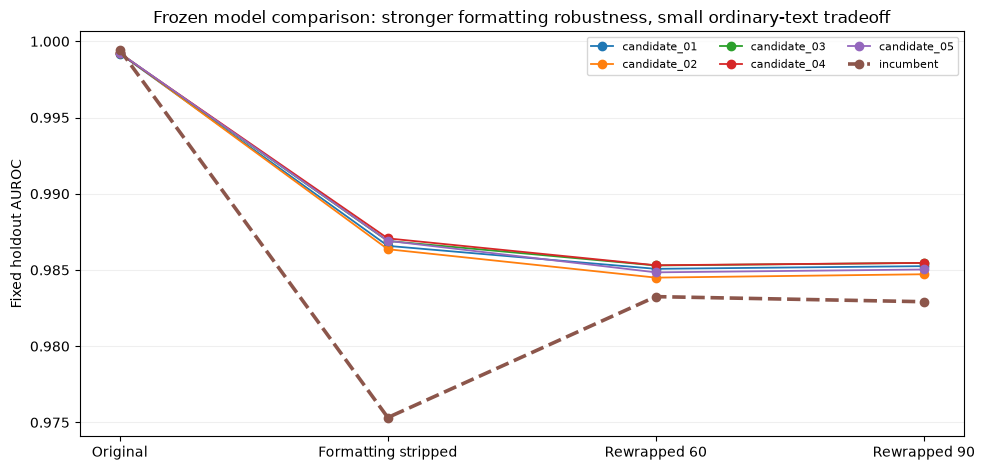

In [5]:
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

measured = pd.read_csv(OUT / 'fixed_holdout_metrics.csv').set_index('candidate')
old_measured = pd.read_csv(OLD / 'official_holdout_metrics.csv')
old_measured = old_measured[old_measured.model == 'corrected_incumbent'].set_index('view')['auc']
comparison = measured[['original', 'canonical', 'wrap60', 'wrap90', 'stress_mean']].copy()
comparison.loc['incumbent'] = [old_measured[k] for k in ['original','canonical','wrap60','wrap90']] + [old_measured[['canonical','wrap60','wrap90']].mean()]
display(comparison.round(6))
fig, ax = plt.subplots(figsize=(10, 4.8))
views = ['original','canonical','wrap60','wrap90']
for name, row in comparison.iterrows():
    ax.plot(range(len(views)), row[views], marker='o', linewidth=2.6 if name=='incumbent' else 1.3,
            linestyle='--' if name=='incumbent' else '-', label=name)
ax.set_xticks(range(len(views)), ['Original','Formatting stripped','Rewrapped 60','Rewrapped 90'])
ax.set_ylabel('Fixed holdout AUROC')
ax.set_title('Frozen model comparison: stronger formatting robustness, small ordinary-text tradeoff')
ax.grid(axis='y', alpha=.2)
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'holdout_comparison.png', dpi=180)
plt.show()


## Final artifact audit and graph update

In [6]:
import subprocess

manifest = json.loads((OUT / 'submission_manifest.json').read_text())
frozen = json.loads((OUT / 'frozen.json').read_text())
recorded_hash = frozen.pop('recipe_sha256')
assert hashlib.sha256(json.dumps(frozen, sort_keys=True).encode()).hexdigest() == recorded_hash == manifest['recipe_sha256']
sample = pd.read_csv(data / 'sample_submission.csv')
assert len(manifest['files']) == 5
for entry in manifest['files']:
    file_path = ROOT / entry['file']
    assert file_path.resolve().is_relative_to(ROOT)
    assert hashlib.sha256(file_path.read_bytes()).hexdigest() == entry['sha256']
    validate_submission(pd.read_csv(file_path), sample)
assert all(delta == 0 for delta in manifest['independent_full_refit_max_deltas'].values())
assert not any((ROOT / file).exists() for file in ['further_tuning.py','test_further_tuning.py','tasks/plan.md','tasks/todo.md'])
assert len(list((OUT / 'submissions').glob('*.csv'))) == 5
print('Verified: five 3,000-row CSVs, ID order, schema, probabilities, hashes, frozen recipe integrity and exact full-data reproducibility.')
print('Development-based upload order:', ', '.join(manifest['upload_order']))
result = subprocess.run(['graphify','update','.'], cwd=ROOT, capture_output=True, text=True)
print(result.stdout)
assert result.returncode == 0, result.stderr


Verified: five 3,000-row CSVs, ID order, schema, probabilities, hashes, frozen recipe integrity and exact full-data reproducibility.
Development-based upload order: candidate_03, candidate_01, candidate_04, candidate_02, candidate_05


Re-extracting code files in . (no LLM needed)...
[graphify] backed up curated graph (4 files) -> 2026-11-08/
[graphify watch] Rebuilt: 15 nodes, 13 edges, 4 communities
[graphify watch] graph.json, graph.html and GRAPH_REPORT.md updated in graphify-out
Code graph updated. For doc/paper/image changes run /graphify --update in your AI assistant.

